# IMDb — Data preparation and data exploration

This notebook runs the project functions (`src/preparation`, `src/exploration`) on the
IMDb dataset and displays their results. Every result is also saved as CSV under
`output/preparation/` and `output/exploration/`.

Prerequisite: bronze tables built with `python -m src.ingestion.convert_to_parquet`.

In [1]:
import sys
sys.path.insert(0, "/home/jovyan/project")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.common import io
from src.common.spark import get_spark
from src.preparation import clean_to_silver, missing_values, quality_checks
from src.exploration import questions as q

io.VERBOSE = False
pd.set_option("display.max_colwidth", 80)
spark = get_spark("imdb_notebook")


def result(name, n=20):
    df = io.RESULTS[name]
    print(f"{name}: {len(df):,} rows")
    display(df.head(n))
    return df

/home/jovyan/.cache/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-78oav0rk because there was an issue with the default path (/home/jovyan/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


# 1. Data preparation

## 1.1 Percentage of nulls, missing or empty records per column

> For each column of each table in the IMDB dataset, calculate the percentage of nulls, missing, or empty records.

In [2]:
missing_values.run(spark)
missing = result("preparation/missing_values", n=60)

preparation/missing_values: 39 rows


,table,column,total_rows,null_count,empty_count,missing_pct
0,name.basics,birthYear,15768361,15083690,0,95.658
1,name.basics,deathYear,15768361,15503465,0,98.320
2,name.basics,knownForTitles,15768361,1909627,0,12.110
3,name.basics,nconst,15768361,0,0,0.000
4,name.basics,primaryName,15768361,87,0,0.001
5,name.basics,primaryProfession,15768361,3204437,0,20.322
6,title.akas,attributes,59957982,59641573,0,99.472
7,title.akas,isOriginalTitle,59957982,0,0,0.000
8,title.akas,language,59957982,19551814,0,32.609
9,title.akas,ordering,59957982,0,0,0.000


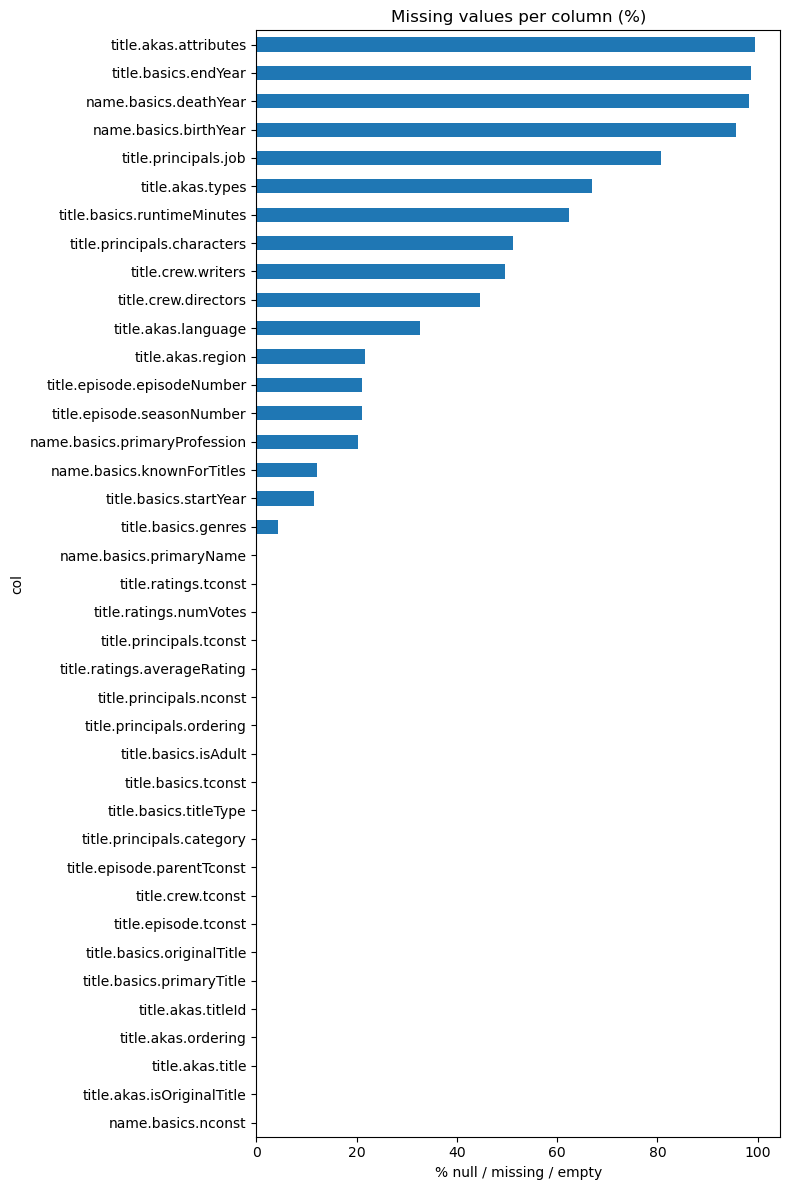

In [3]:
pivot = missing.assign(col=missing["table"] + "." + missing["column"]).set_index("col")["missing_pct"]
ax = pivot.sort_values().plot.barh(figsize=(8, 12), title="Missing values per column (%)")
ax.set_xlabel("% null / missing / empty")
plt.tight_layout()

## 1.2 Top five columns

> Which five columns across the entire dataset have the highest percentage of null values?

In [4]:
result("preparation/top5_missing_columns")

preparation/top5_missing_columns: 5 rows


,table,column,total_rows,null_count,empty_count,missing_pct
0,title.akas,attributes,59957982,59641573,0,99.472
1,title.basics,endYear,12902085,12738467,0,98.732
2,name.basics,deathYear,15768361,15503465,0,98.320
3,name.basics,birthYear,15768361,15083690,0,95.658
4,title.principals,job,102539871,82740671,0,80.691


,table,column,total_rows,null_count,empty_count,missing_pct
0,title.akas,attributes,59957982,59641573,0,99.472
1,title.basics,endYear,12902085,12738467,0,98.732
2,name.basics,deathYear,15768361,15503465,0,98.320
3,name.basics,birthYear,15768361,15083690,0,95.658
4,title.principals,job,102539871,82740671,0,80.691


## 1.3 Other data quality issues

> Identify other data quality issues for the dataset such as principals who died before they were born, foreign keys with missing parent records, etc.

In [5]:
quality_checks.run(spark)
issues = result("preparation/quality_issues", n=50)

name.basics       death_before_birth                     27 (0.0002%)


name.basics       implausible_lifespan                    2 (0.0%)


name.basics       alive_over_120                      2,793 (0.0177%)


name.basics       year_in_future                          0 (0.0%)


name.basics       non_numeric_year                        0 (0.0%)


name.basics       duplicate_nconst                        0 (0.0%)


... (23 outputs left out)

title.akas        orphan_title_id                        33 (0.0001%)


title.akas        invalid_is_original                     0 (0.0%)


preparation/quality_issues: 31 rows


,table,check,description,violations,base_rows,violation_pct
0,name.basics,death_before_birth,deathYear < birthYear,27,15768361,0.0002
1,name.basics,implausible_lifespan,deathYear - birthYear > 120,2,15768361,0.0000
2,name.basics,alive_over_120,no deathYear and birthYear < 1906,2793,15768361,0.0177
3,name.basics,year_in_future,birthYear or deathYear > 2026,0,15768361,0.0000
4,name.basics,non_numeric_year,birthYear/deathYear present but not an integer,0,15768361,0.0000
5,name.basics,duplicate_nconst,nconst appearing more than once,0,15768361,0.0000
6,title.basics,duplicate_tconst,tconst appearing more than once,0,12902085,0.0000
7,title.basics,end_before_start,endYear < startYear,0,12902085,0.0000
8,title.basics,runtime_non_positive,runtimeMinutes <= 0,4,12902085,0.0000
9,title.basics,runtime_over_24h,runtimeMinutes > 1440,209,12902085,0.0016


In [6]:
for name in ["death_before_birth", "died_before_title", "born_after_title", "end_before_start"]:
    key = f"preparation/examples_{name}"
    if key in io.RESULTS:
        result(key, n=5)

preparation/examples_death_before_birth: 20 rows


,nconst,primaryName,birthYear,deathYear,birthYear__raw,deathYear__raw
0,nm5787531,Lea Tormis,1932,1925,1932,1925
1,nm0034922,Aristophanes,450,388,450,388
2,nm12436700,Aristotle,384,322,384,322
3,nm0686974,Titus Maccius Plautus,254,184,254,184
4,nm0541940,A. Maneck,1899,1867,1899,1867


preparation/examples_died_before_title: 20 rows


,nconst,tconst,category,primaryTitle,startYear,primaryName,birthYear,deathYear
0,nm0000004,tt1093389,actor,Saturday Night Live: The Best of Dan Aykroyd,2005,John Belushi,1949,1982
1,nm0000004,tt0088790,writer,The Best of John Belushi,1985,John Belushi,1949,1982
2,nm0000004,tt1093390,actor,Saturday Night Live: The Best of Gilda Radner,2005,John Belushi,1949,1982
3,nm0000004,tt3377584,actor,Saturday Night Live: Thanksgiving,2013,John Belushi,1949,1982
4,nm0000004,tt3513114,actor,SNL Sports Spectacular,2014,John Belushi,1949,1982


preparation/examples_born_after_title: 20 rows


,nconst,tconst,category,primaryTitle,startYear,primaryName,birthYear,deathYear
0,nm0002301,tt0020030,composer,The Iron Mask,1929,Carl Davis,1936,2023
1,nm0002301,tt0016641,composer,Ben-Hur: A Tale of the Christ,1925,Carl Davis,1936,2023
2,nm0002301,tt0017437,composer,The Strong Man,1926,Carl Davis,1936,2023
3,nm0002301,tt0015772,composer,The Eagle,1925,Carl Davis,1936,2023
4,nm0002301,tt0015624,composer,The Big Parade,1925,Carl Davis,1936,2023


## 1.4 Handling the issues (silver layer)

> Design and implement a way to handle these values.

The rules applied are listed in the docstring of `src/preparation/clean_to_silver.py`.
The silver layer is normally built by `python -m src.preparation.clean_to_silver`; set `RUN_CLEANING = True` to rebuild it from here.

In [7]:
RUN_CLEANING = False
if RUN_CLEANING:
    clean_to_silver.run(spark)
    result("preparation/cleaning_summary")

In [8]:
from pyspark.sql import functions as F
from src.common.io import read_silver

flags = (
    read_silver(spark, "name_basics").select(F.explode("dq_flags").alias("flag")).withColumn("table", F.lit("name_basics"))
    .unionByName(read_silver(spark, "title_basics").select(F.explode("dq_flags").alias("flag")).withColumn("table", F.lit("title_basics")))
    .unionByName(read_silver(spark, "title_principals").select(F.explode("dq_flags").alias("flag")).withColumn("table", F.lit("title_principals")))
    .groupBy("table", "flag").count().orderBy("table", F.desc("count"))
)
display(flags.toPandas())

,table,flag,count
0,name_basics,death_before_birth,27
1,title_basics,invalid_runtime,213
2,title_principals,died_before_title,229691
3,title_principals,born_after_title,3108


# 2. Data exploration

## 2.1 Runtime outliers by genre

> Find all feature-length movies by genre whose length is notably different than the average length of movies in that genre.

In [4]:
q.q1_runtime_outliers(spark)
by_genre = result("exploration/q1_runtime_outliers_by_genre", n=30)
outliers = result("exploration/q1_runtime_outliers", n=10)

exploration/q1_runtime_outliers_by_genre: 27 rows


,genre,n_movies,avg_runtime,std_runtime,n_outliers,n_longer,n_shorter
0,Drama,196414,95.9,27.5,5716,5716,0
1,Documentary,115845,76.6,30.2,2145,2145,0
2,Comedy,96482,93.1,22.3,4628,3586,1042
3,Romance,42414,99.1,25.1,2042,1813,229
4,Action,40300,101.1,31.3,1146,1146,0
5,Crime,34565,95.5,25.6,1174,1165,9
6,Thriller,34013,96.1,21.7,2084,1386,698
7,Horror,30667,88.6,22.3,700,696,4
8,Adventure,24031,93.0,30.6,633,633,0
9,Mystery,16457,93.9,24.8,449,446,3


exploration/q1_runtime_outliers: 24,062 rows


,genre,tconst,primaryTitle,startYear,runtimeMinutes,avg_runtime,z_score,numVotes
0,Action,tt45643419,Ooio Aifujairea: Lifedesign,2025.0,1440,101.1,42.78,NaN
1,Action,tt0004052,The Hazards of Helen,1914.0,1428,101.1,42.39,125.0
2,Action,tt0131597,Split,2004.0,700,101.1,19.13,34.0
3,Action,tt12669540,Marathon Wars,NaN,600,101.1,15.94,NaN
4,Action,tt39392193,The Longest Movie on Earth!?: The Narwallus Movie!,2016.0,600,101.1,15.94,NaN
5,Action,tt37937538,Pedazo del Alma,2024.0,540,101.1,14.02,NaN
6,Action,tt42728310,Cinematic Carnage: The Movie,2026.0,486,101.1,12.30,NaN
7,Action,tt0006206,Les Vampires,1915.0,421,101.1,10.22,5941.0
8,Action,tt0009204,The House of Hate,1918.0,410,101.1,9.87,32.0
9,Action,tt0007932,The Fatal Ring,1917.0,400,101.1,9.55,17.0


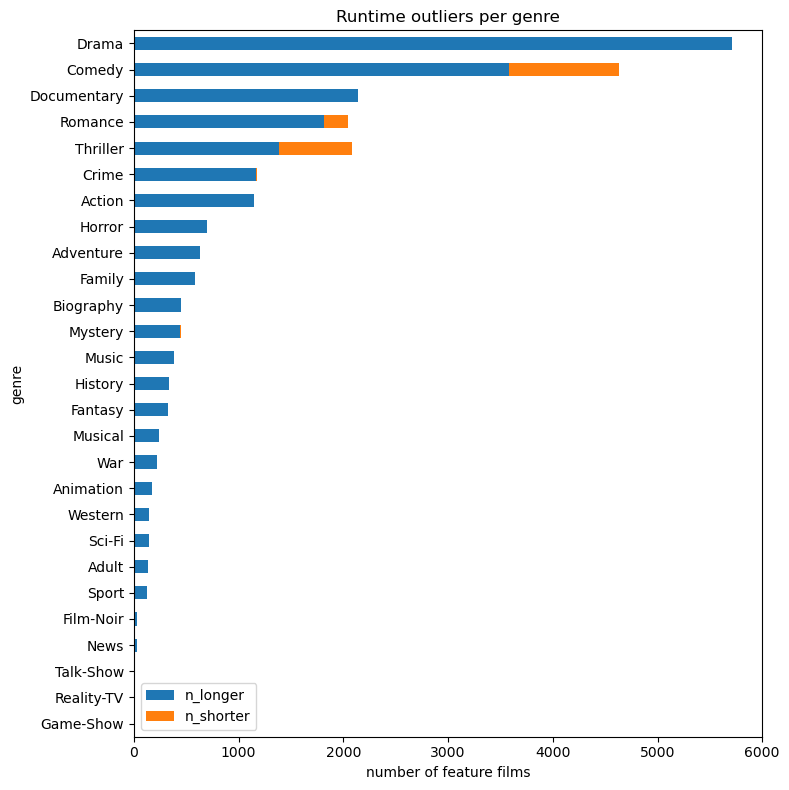

In [5]:
ax = by_genre.set_index("genre")[["n_longer", "n_shorter"]].sort_values("n_longer").plot.barh(
    stacked=True, figsize=(8, 8), title="Runtime outliers per genre")
ax.set_xlabel("number of feature films")
plt.tight_layout()

## 2.2 Top three genres per year (1980–2025)

> What are the top three most popular movie genres for each year between 1980 and 2025?

In [11]:
q.q2_top3_genres(spark)
top3 = result("exploration/q2_top3_genres_per_year", n=15)

exploration/q2_top3_genres_per_year: 138 rows


,year,genre,n_movies,total_votes,avg_rating,rank
0,1980,Drama,1075,3158430,6.13,1
1,1980,Adventure,137,2479615,5.90,2
2,1980,Horror,143,2067048,5.22,3
3,1981,Adventure,154,2248577,6.11,1
4,1981,Drama,1034,1707582,6.20,2
5,1981,Horror,159,1271749,5.44,3
6,1982,Drama,1124,3069942,6.16,1
7,1982,Sci-Fi,53,2453337,5.49,2
8,1982,Action,295,1870848,5.77,3
9,1983,Drama,1145,2916399,6.17,1


In [12]:
top3.pivot(index="year", columns="rank", values="genre").rename(columns=lambda r: f"#{r}")

rank,#1,#2,#3
year,,,
1980,Drama,Adventure,Horror
1981,Adventure,Drama,Horror
1982,Drama,Sci-Fi,Action
1983,Drama,Action,Adventure
1984,Action,Drama,Adventure
1985,Comedy,Adventure,Drama
1986,Drama,Adventure,Comedy
1987,Drama,Comedy,Action
1988,Drama,Comedy,Action


## 2.3 Top three genres compared to the rest

> Compare the results from the previous question. How do the top three genres compare to the rest of the genres of movies in a given year?

In [13]:
q.q3_top3_vs_rest(spark)
per_year = result("exploration/q3_top3_vs_rest_per_year", n=10)
result("exploration/q3_top3_vs_rest_overall")
result("exploration/q3_genre_frequency_in_top3")

exploration/q3_top3_vs_rest_per_year: 92 rows


,year,group,n_movies,total_votes,n_genres,vote_share_pct,votes_per_movie
0,1980,rest,2304,9657628,21,55.6,4192.0
1,1980,top3,1355,7705093,3,44.4,5686.0
2,1981,rest,2423,6020711,20,53.5,2485.0
3,1981,top3,1347,5227908,3,46.5,3881.0
4,1982,rest,2339,9515713,19,56.3,4068.0
5,1982,top3,1472,7394127,3,43.7,5023.0
6,1983,rest,2301,8171283,19,54.1,3551.0
7,1983,top3,1601,6921577,3,45.9,4323.0
8,1984,rest,2391,11878038,19,55.3,4968.0
9,1984,top3,1552,9612589,3,44.7,6194.0


exploration/q3_top3_vs_rest_overall: 2 rows


,group,avg_rating,avg_votes_per_movie,avg_runtime
0,rest,6.14,7047.0,93.7
1,top3,6.04,7895.0,100.4


exploration/q3_genre_frequency_in_top3: 8 rows


,genre,years_in_top3
0,Drama,46
1,Comedy,34
2,Action,29
3,Adventure,16
4,Crime,9
5,Horror,2
6,Thriller,1
7,Sci-Fi,1


,genre,years_in_top3
0,Drama,46
1,Comedy,34
2,Action,29
3,Adventure,16
4,Crime,9
5,Horror,2
6,Thriller,1
7,Sci-Fi,1


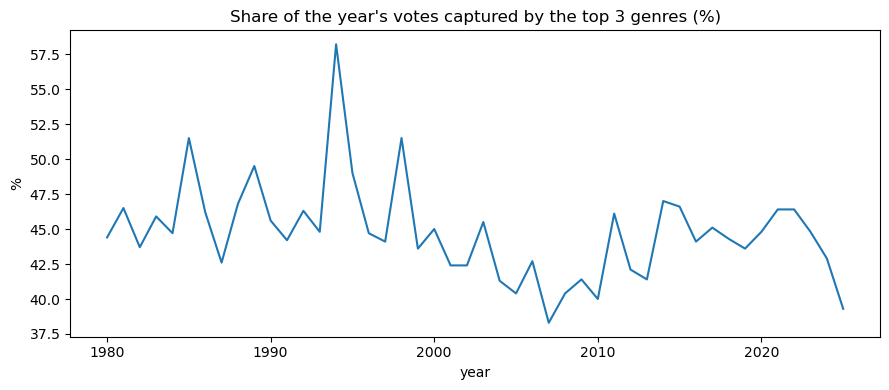

In [14]:
share = per_year[per_year["group"] == "top3"].set_index("year")["vote_share_pct"]
ax = share.plot(figsize=(9, 4), title="Share of the year's votes captured by the top 3 genres (%)")
ax.set_ylabel("%")
plt.tight_layout()

## 2.4 One-hit directors

> List all directors who have directed exactly one movie with a rating >= 8.0 but who have multiple other movies directed with an average rating of <= 6.0.

In [15]:
q.q4_one_hit_directors(spark)
result("exploration/q4_one_hit_directors", n=30)

exploration/q4_one_hit_directors: 188 rows


,nconst,primaryName,n_other_movies,avg_other_rating,hit_title,hit_year,hit_rating
0,nm0490487,Wai Keung Lau,43,5.72,Infernal Affairs,2002,8.0
1,nm0080315,Mahesh Bhatt,36,5.68,Saaransh,1984,8.1
2,nm0435050,Shaji Kailas,35,5.33,Aaram Thamburan,1997,8.1
3,nm0700872,Puri Jagannadh,33,5.52,Pokiri,2006,8.0
4,nm1326535,Sundar C.,25,5.68,Anbe Sivam,2003,8.6
5,nm0471452,Suresh Krishna,24,5.98,Baasha,1995,8.2
6,nm0001675,Robert Rodriguez,23,5.90,Sin City,2005,8.0
7,nm3359146,Rabi Kinagi,23,5.76,Suna Panjuri,1995,9.0
8,nm2321771,Smeep Kang,22,5.84,Carry on Jatta,2012,8.3
9,nm0000814,John G. Avildsen,21,5.78,Rocky,1976,8.1


,nconst,primaryName,n_other_movies,avg_other_rating,hit_title,hit_year,hit_rating
0,nm0490487,Wai Keung Lau,43,5.72,Infernal Affairs,2002,8.0
1,nm0080315,Mahesh Bhatt,36,5.68,Saaransh,1984,8.1
2,nm0435050,Shaji Kailas,35,5.33,Aaram Thamburan,1997,8.1
3,nm0700872,Puri Jagannadh,33,5.52,Pokiri,2006,8.0
4,nm1326535,Sundar C.,25,5.68,Anbe Sivam,2003,8.6
...,...,...,...,...,...,...,...
183,nm3649519,Carolina Durão,2,5.35,New Year's Special,2023,8.4
184,nm0132257,Bruce Campbell,2,5.75,Ernie & Emma,2026,8.4
185,nm2614650,Jeff Kaufman,2,4.55,Nasrin,2020,8.1
186,nm0204628,Garth Davis,2,5.65,Lion,2016,8.0


## 2.5 Series that declined

> Identify television series with at least three seasons consisting of >=10 episodes where the worst episode occurred in the last season and the best episode occurred within the first two seasons.

In [16]:
q.q5_declining_series(spark)
result("exploration/q5_declining_series", n=30)

exploration/q5_declining_series: 639 rows


,parentTconst,primaryTitle,startYear,n_full_seasons,last_season,best,worst
0,tt8560918,The Queen of Flow,2018,3,3,9.8,1.1
1,tt4508902,One Punch Man,2015,3,3,9.5,1.6
2,tt34174211,Celebrity Substitute,2024,3,3,9.6,2.3
3,tt1856010,House of Cards,2013,5,6,9.5,2.5
4,tt0200337,Family Law,1999,3,3,9.4,2.7
5,tt0050022,The Gumby Show,1956,3,3,8.1,1.4
6,tt0118252,All Dogs Go to Heaven: The Series,1996,3,3,9.2,2.6
7,tt19638434,FRO Thizzle Reviews,2022,5,5,10.0,3.6
8,tt33145195,Margarita,2024,3,3,9.4,3.1
9,tt5189554,Soy Luna,2016,4,4,9.1,2.8


,parentTconst,primaryTitle,startYear,n_full_seasons,last_season,best,worst
0,tt8560918,The Queen of Flow,2018,3,3,9.8,1.1
1,tt4508902,One Punch Man,2015,3,3,9.5,1.6
2,tt34174211,Celebrity Substitute,2024,3,3,9.6,2.3
3,tt1856010,House of Cards,2013,5,6,9.5,2.5
4,tt0200337,Family Law,1999,3,3,9.4,2.7
...,...,...,...,...,...,...,...
634,tt2778780,The Most Popular Girls in School,2012,5,5,9.5,9.1
635,tt5735236,Blood Banquet Theatre,2005,6,9,9.6,9.2
636,tt0434735,Yabanci Damat,2004,3,3,9.8,9.5
637,tt21257646,Riddiculous,2022,3,3,7.4,7.2


## 2.6 Success across languages

> Find any actors/actresses who have achieved success across films in multiple distinct languages (e.g. been in a successful film originally in French and English). Additionally, list all actors/actresses who have achieved success in movies in >=3 languages (e.g. French, German, and English).

In [17]:
q.q6_multilingual_actors(spark)
result("exploration/q6_actors_2plus_languages", n=15)
result("exploration/q6_actors_3plus_languages", n=50)

0 films to look up on Wikidata


exploration/q6_actors_2plus_languages: 2,240 rows


,nconst,primaryName,n_languages,languages,n_successful_movies
0,nm0474609,Atul Kulkarni,6,hi|kn|ml|mr|ta|te,12
1,nm0004486,Bruno Ganz,6,de|el|en|is|it|sv,11
2,nm0700869,Amrish Puri,5,en|hi|ml|ta|te,25
3,nm0001884,Max von Sydow,5,en|fr|it|no|sv,23
4,nm0728262,Mukesh Rishi,5,hi|kn|mr|ta|te,17
5,nm1299510,Genelia Deshmukh,5,hi|ml|mr|ta|te,12
6,nm0154122,Dhritiman Chatterjee,5,bn|en|hi|ml|ta,12
7,nm0626259,Franco Nero,5,de|en|es|it|sr,10
8,nm0368990,Rohini Hattangadi,5,en|hi|mr|ta|te,10
9,nm0419685,Jaya Prada,5,hi|kn|ml|ta|te,8


exploration/q6_actors_3plus_languages: 326 rows


,nconst,primaryName,n_languages,languages,n_successful_movies
0,nm0474609,Atul Kulkarni,6,hi|kn|ml|mr|ta|te,12
1,nm0004486,Bruno Ganz,6,de|el|en|is|it|sv,11
2,nm0700869,Amrish Puri,5,en|hi|ml|ta|te,25
3,nm0001884,Max von Sydow,5,en|fr|it|no|sv,23
4,nm0728262,Mukesh Rishi,5,hi|kn|mr|ta|te,17
5,nm1299510,Genelia Deshmukh,5,hi|ml|mr|ta|te,12
6,nm0154122,Dhritiman Chatterjee,5,bn|en|hi|ml|ta,12
7,nm0626259,Franco Nero,5,de|en|es|it|sr,10
8,nm0368990,Rohini Hattangadi,5,en|hi|mr|ta|te,10
9,nm0419685,Jaya Prada,5,hi|kn|ml|ta|te,8


,nconst,primaryName,n_languages,languages,n_successful_movies
0,nm0474609,Atul Kulkarni,6,hi|kn|ml|mr|ta|te,12
1,nm0004486,Bruno Ganz,6,de|el|en|is|it|sv,11
2,nm0700869,Amrish Puri,5,en|hi|ml|ta|te,25
3,nm0001884,Max von Sydow,5,en|fr|it|no|sv,23
4,nm0728262,Mukesh Rishi,5,hi|kn|mr|ta|te,17
...,...,...,...,...,...
321,nm5011084,Amir El-Masry,3,arz|da|en,3
322,nm0001934,Kabir Bedi,3,en|hi|ml,3
323,nm3844346,Wamiqa Gabbi,3,hi|ml|pa,3
324,nm1426805,Salman Shahid,3,hi|pa|ur,3


## 2.7 Actors whose popularity peaked early

> Find all actors/actresses who have been in movies for 20+ years and at least 15 or more movies whose popularity peaked early in their career (e.g. had their highest rated movies early in their career as compared to later.)

In [18]:
q.q7_early_peak_actors(spark)
early = result("exploration/q7_early_peak_actors", n=30)

exploration/q7_early_peak_actors: 4,495 rows


,nconst,primaryName,first_year,last_year,n_movies,peak_year,peak_rating,avg_first_half,avg_second_half
0,nm0000043,Veronica Lake,1941,1970,20,1941,7.9,6.42,2.50
1,nm0025618,Mahesh Anand,1988,2019,33,1991,7.4,5.47,1.90
2,nm0437053,Kanakalatha,1986,2017,16,1993,7.9,6.48,2.93
3,nm0939961,Robert Woods,1966,2016,22,1966,6.1,5.12,1.70
4,nm0738553,Artur Rolén,1918,1967,20,1918,7.2,7.20,3.84
5,nm0060692,Aleksey Batalov,1954,2007,16,1957,8.3,7.35,4.05
6,nm0562770,Ken Maynard,1931,1970,19,1944,6.7,5.97,2.70
7,nm0936295,Norman Wisdom,1953,2002,18,1963,6.9,6.31,3.20
8,nm0044600,Saroja Devi B.,1958,2023,16,1977,8.9,8.01,5.07
9,nm4457317,Sadek Bachchu,1994,2020,16,1997,8.2,8.05,5.17


## 2.8 Multi-talented professionals

> Identify film professionals who can be considered "multi-talented" (e.g. some combo of writer/director/actor). How do these individuals perform when performing multiple roles on the same project (e.g. directing and acting in the same movie)?

In [19]:
q.q8_multi_talented(spark)
comparison = result("exploration/q8_multi_role_vs_single_role")
result("exploration/q8_per_person_gap")
result("exploration/q8_top_multi_talented", n=20)

exploration/q8_multi_role_vs_single_role: 8 rows


,career_profile,situation,n_people,n_titles,avg_rating
0,actor+director,multiple roles on the title,356,897,5.692
1,actor+director,single role on the title,437,9839,5.979
2,actor+director+writer,multiple roles on the title,1479,11309,5.868
3,actor+director+writer,single role on the title,1388,20894,5.877
4,actor+writer,multiple roles on the title,1065,3458,5.642
5,actor+writer,single role on the title,1193,18265,5.843
6,director+writer,multiple roles on the title,7921,40809,6.001
7,director+writer,single role on the title,5744,30680,5.972


exploration/q8_per_person_gap: 1 rows


,n_people,mean_rating_gap_multi_minus_single,pct_people_better_in_multi
0,8473,0.048,53.1


exploration/q8_top_multi_talented: 3,471 rows


,primaryName,n_multi_titles,avg_multi,avg_single
0,Jesús Franco,127,4.65,4.45
1,Jing Wong,91,5.65,5.72
2,Yōji Yamada,63,6.89,6.89
3,Giannis Dalianidis,61,5.98,5.94
4,Jean-Luc Godard,60,6.44,6.15
5,Carlo Vanzina,55,4.85,4.83
6,Woody Allen,54,6.89,5.69
7,Cheh Chang,53,6.47,6.34
8,Claude Chabrol,47,6.54,6.09
9,Kader Khan,46,5.73,5.39


,primaryName,n_multi_titles,avg_multi,avg_single
0,Jesús Franco,127,4.65,4.45
1,Jing Wong,91,5.65,5.72
2,Yōji Yamada,63,6.89,6.89
3,Giannis Dalianidis,61,5.98,5.94
4,Jean-Luc Godard,60,6.44,6.15
...,...,...,...,...
3466,Thomas Vincent,5,6.12,5.30
3467,Saran,5,6.08,6.07
3468,R. Madhesh,5,5.18,7.45
3469,Ryan Bellgardt,5,3.74,3.74


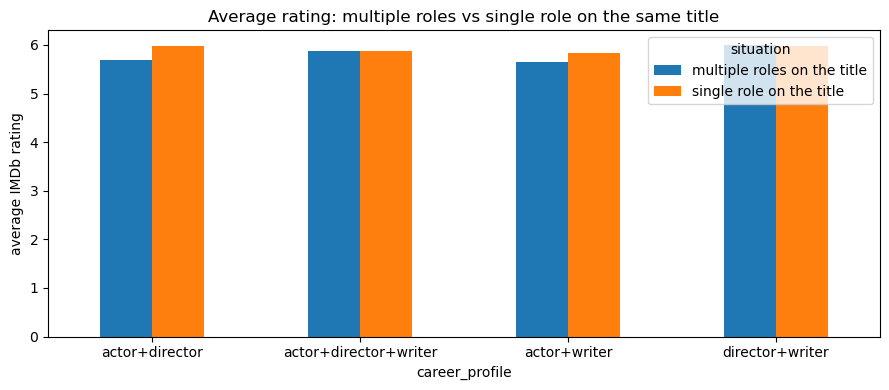

In [20]:
ax = comparison.pivot(index="career_profile", columns="situation", values="avg_rating").plot.bar(
    figsize=(9, 4), title="Average rating: multiple roles vs single role on the same title")
ax.set_ylabel("average IMDb rating")
plt.xticks(rotation=0)
plt.tight_layout()

In [21]:
spark.stop()